<a href="https://colab.research.google.com/github/Xyrfo/Pembelajaran-Mesin/blob/main/JS09/tugas_lab2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tugas Lab 2 - JS09 Approximate Nearest Neighbors
## Pencarian Track Terdekat pada Dataset Spotify

**Nama:** Rifo Anggi Barbara Danuarta
**NIM:** 244107020063
**Kelas:** 3F

## Tujuan

Lakukan percobaan penggunaan **ANNOY**, **FAISS**, dan **HNSWLIB** pada dataset sekunder berukuran besar (Spotify Songs with Attributes and Lyrics dari Kaggle), lalu bandingkan hasilnya dengan **Exact NN**.

Sesuai instruksi modul:

1. Download data dan load CSV-nya (pilih dataset yang pertama dari dua dataset) - di notebook ini unduhan dilakukan otomatis via `kagglehub`, tanpa login Kaggle.
2. Pilih hanya fitur numerik, lalu normalisasi menggunakan **StandardScaler**.
3. Lakukan pencarian track terdekat dan bandingkan hasilnya.
4. Bandingkan Exact NN vs ANNOY vs FAISS vs HNSW.




## Alur Pengerjaan

1. Setup library.
2. Unduh dataset via `kagglehub` dan pilih CSV atribut.
3. Pra-pengolahan: fitur numerik + StandardScaler.
4. Pilih 5 track query.
5. Exact NN (baseline), ANNOY, FAISS, HNSW.
6. Perbandingan waktu build/query dan recall terhadap Exact NN.
7. Analisis dan kesimpulan.
8. **[TAMBAHAN]** Sensitivitas parameter dan skalabilitas ukuran data.


In [1]:
!pip install -q annoy faiss-cpu hnswlib

import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

import faiss
from annoy import AnnoyIndex
import hnswlib
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
pd.options.display.max_colwidth = 80

SEED = 24
K = 10

print('Setup selesai.')


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Setup selesai.


## 1. Unduh Dataset via Kagglehub

Dataset publik diunduh langsung tanpa login. Setelah diunduh, notebook menampilkan semua CSV yang ditemukan lalu memilih **CSV atribut** (`spotify_songs.csv`) sesuai instruksi modul: pilih dataset yang pertama.


In [2]:
import kagglehub

DATASET_SLUG = 'bwandowando/spotify-songs-with-attributes-and-lyrics'
data_root = kagglehub.dataset_download(DATASET_SLUG)
print('Dataset tersimpan di:', data_root)

import os
csv_files = []
for root, dirs, files in os.walk(data_root):
    for fname in files:
        if fname.lower().endswith('.csv'):
            csv_files.append(os.path.join(root, fname))
csv_files.sort()
print('CSV yang ditemukan:')
for c in csv_files:
    print(' -', c)

csv_path = None
for c in csv_files:
    if os.path.basename(c).lower() == 'spotify_songs.csv':
        csv_path = c
        break
if csv_path is None:
    csv_path = csv_files[0]
print('CSV yang dipakai:', csv_path)


100%|██████████| 894M/894M [00:12<00:00, 75.6MB/s]

Extracting files...


Dataset tersimpan di: /root/.cache/kagglehub/datasets/bwandowando/spotify-songs-with-attributes-and-lyrics/versions/20
CSV yang ditemukan:
 - /root/.cache/kagglehub/datasets/bwandowando/spotify-songs-with-attributes-and-lyrics/versions/20/songs_with_attributes_and_lyrics.csv
 - /root/.cache/kagglehub/datasets/bwandowando/spotify-songs-with-attributes-and-lyrics/versions/20/songs_with_lyrics_and_timestamps.csv
CSV yang dipakai: /root/.cache/kagglehub/datasets/bwandowando/spotify-songs-with-attributes-and-lyrics/versions/20/songs_with_attributes_and_lyrics.csv


In [3]:
# Peek kolom dulu (hemat memori), lalu load hanya kolom yang dibutuhkan
peek = pd.read_csv(csv_path, nrows=5)
print('Semua kolom:', list(peek.columns))

FEATURES = ['danceability', 'energy', 'loudness', 'speechiness',
            'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']
LABEL_COLS = [c for c in ['track_id', 'track_name', 'track_artist'] if c in peek.columns]
use_cols = FEATURES + LABEL_COLS
print('Kolom yang di-load:', use_cols)

df = pd.read_csv(csv_path, usecols=use_cols)
print('Ukuran data:', df.shape)
print('Perkiraan memori (MB):', round(df.memory_usage(deep=True).sum() / 1e6, 1))
df.head()


Semua kolom: ['id', 'name', 'album_name', 'artists', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_ms', 'lyrics']
Kolom yang di-load: ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']
Ukuran data: (955320, 9)
Perkiraan memori (MB): 68.8


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
0,0.415,0.6050,-11.157,0.0575,0.00116,0.838000,0.4710,0.193,100.059
1,0.788,0.6480,-9.135,0.3150,0.90000,0.000000,0.1760,0.287,79.998
2,0.000,0.0354,-20.151,0.0000,0.90800,0.000000,0.4790,0.000,0.000
3,0.657,0.8820,-6.340,0.0385,0.00740,0.000013,0.0474,0.939,123.588
4,0.659,0.8930,-8.531,0.0411,0.09220,0.000019,0.0534,0.951,123.600


## 2. Pra-Pengolahan

Pilih hanya fitur numerik, buang baris dengan nilai kosong, lalu normalisasi dengan **StandardScaler** agar setiap fitur punya skala yang setara.


In [4]:
before = len(df)
df = df.dropna(subset=FEATURES).reset_index(drop=True)
print(f'Baris dibuang karena NaN: {before - len(df)}')

X = df[FEATURES].values.astype('float64')
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X).astype('float32')

D = X_scaled.shape[1]
N = X_scaled.shape[0]
print('Dimensi fitur:', D)
print('Jumlah data  :', N)
print('Rata-rata ~ 0:', np.allclose(X_scaled.mean(axis=0), 0, atol=1e-4))
print('Std ~ 1      :', np.allclose(X_scaled.std(axis=0), 1, atol=1e-4))


Baris dibuang karena NaN: 0
Dimensi fitur: 9
Jumlah data  : 955320
Rata-rata ~ 0: True
Std ~ 1      : True


## 3. Fungsi Bantu dan Pemilihan Track Query

Digunakan **5 track query** (bukan 1) agar perbandingan waktu dan recall lebih adil dan tidak tergantung satu titik saja.


In [5]:
rng = np.random.default_rng(SEED)
Q_IDS = sorted(rng.choice(N, size=5, replace=False).tolist())
print('Indeks query:', Q_IDS)


def label(i):
    row = df.iloc[int(i)]
    name = str(row['track_name']) if 'track_name' in df.columns else f'row {i}'
    artist = str(row['track_artist']) if 'track_artist' in df.columns else ''
    return f'{name} - {artist}' if artist else name


def drop_self(ids, q_idx, k=K):
    return [int(i) for i in ids if int(i) != int(q_idx)][:k]


def recall_at_k(pred_ids, exact_ids, k=K):
    return len(set(pred_ids) & set(exact_ids)) / k


for q in Q_IDS:
    print(f'  [{q}] {label(q)}')


Indeks query: [315511, 365575, 387073, 717627, 749588]
  [315511] row 315511
  [365575] row 365575
  [387073] row 387073
  [717627] row 717627
  [749588] row 749588


In [6]:
# Helper generik (dipakai ulang di bagian utama dan TAMBAHAN)
def run_exact(Xmat, q_idx, k=K):
    nn = NearestNeighbors(n_neighbors=k + 1, algorithm='brute', metric='euclidean').fit(Xmat)
    t0 = time.time()
    _, I = nn.kneighbors(Xmat[q_idx:q_idx + 1])
    dt = time.time() - t0
    return drop_self(I[0], q_idx, k), dt


def build_annoy(Xmat, n_trees):
    index = AnnoyIndex(Xmat.shape[1], 'euclidean')
    for i, v in enumerate(Xmat):
        index.add_item(i, v)
    t0 = time.time()
    index.build(n_trees)
    return index, time.time() - t0


def query_annoy(index, qvec, q_idx, k=K):
    t0 = time.time()
    ids = index.get_nns_by_vector(qvec, k + 1)
    return drop_self(ids, q_idx, k), time.time() - t0


def build_faiss_flat(Xmat):
    index = faiss.IndexFlatL2(Xmat.shape[1])
    t0 = time.time()
    index.add(np.ascontiguousarray(Xmat))
    return index, time.time() - t0


def query_faiss(index, qvec, q_idx, k=K):
    t0 = time.time()
    _, I = index.search(qvec.reshape(1, -1), k + 1)
    return drop_self(I[0], q_idx, k), time.time() - t0


def build_hnsw(Xmat, ef_construction=100, M=16):
    index = hnswlib.Index(space='l2', dim=Xmat.shape[1])
    t0 = time.time()
    index.init_index(max_elements=Xmat.shape[0], ef_construction=ef_construction, M=M)
    index.add_items(Xmat)
    return index, time.time() - t0


def query_hnsw(index, qvec, q_idx, k=K, ef=50):
    index.set_ef(ef)
    t0 = time.time()
    labels, _ = index.knn_query(qvec.reshape(1, -1), k=k + 1)
    return drop_self(labels[0], q_idx, k), time.time() - t0


print('Helper siap.')


Helper siap.


## 4. Exact NN (Baseline)

Exact NN memakai brute-force Euclidean dari scikit-learn. Hasilnya menjadi acuan (ground truth) untuk menghitung recall metode ANN.


In [7]:
exact_ids = {}
exact_times = []
for q in Q_IDS:
    ids, dt = run_exact(X_scaled, q)
    exact_ids[q] = ids
    exact_times.append(dt)
    print(f'Query [{q}] -> {ids}')

t_exact_avg = float(np.mean(exact_times))
print('Rata-rata waktu query Exact NN:', round(t_exact_avg, 5), 'detik')


Query [315511] -> [256906, 472159, 31907, 539046, 87404, 810069, 182907, 507505, 507511, 858990]
Query [365575] -> [881329, 61556, 78766, 449717, 918607, 198691, 174685, 351975, 174622, 321275]
Query [387073] -> [282178, 92971, 869200, 824144, 279933, 180066, 639883, 698929, 429314, 97301]
Query [717627] -> [717628, 866847, 572764, 297249, 692212, 631931, 569258, 720453, 830119, 545977]
Query [749588] -> [947712, 547167, 778513, 597309, 536255, 154185, 27054, 54931, 756298, 844320]
Rata-rata waktu query Exact NN: 0.04868 detik


## 5. ANNOY

ANNOY dibangun dengan `n_trees=10` dan jarak **euclidean** (setara dengan metric Exact NN sehingga perbandingan recall adil; boilerplate modul memakai `angular`, yang setara Euclidean pada vektor ternormalisasi).


In [8]:
annoy_index, t_annoy_build = build_annoy(X_scaled, n_trees=10)
print('Build ANNOY:', round(t_annoy_build, 2), 'detik')

annoy_ids = {}
annoy_times = []
for q in Q_IDS:
    ids, dt = query_annoy(annoy_index, X_scaled[q], q)
    annoy_ids[q] = ids
    annoy_times.append(dt)
t_annoy_avg = float(np.mean(annoy_times))
print('Rata-rata waktu query:', round(t_annoy_avg, 6), 'detik')
print('Contoh hasil query', Q_IDS[0], '->', annoy_ids[Q_IDS[0]])


Build ANNOY: 16.2 detik
Rata-rata waktu query: 0.000123 detik
Contoh hasil query 315511 -> [472159, 31907, 539046, 810069, 182907, 858990, 124349, 684449, 30156, 115012]


## 6. FAISS (IndexFlatL2)

FAISS Flat memakai jarak L2. Pencarian tetap exact, tetapi implementasinya sangat cepat karena memakai SIMD/BLAS.


In [9]:
faiss_index, t_faiss_build = build_faiss_flat(X_scaled)
print('Build FAISS Flat:', round(t_faiss_build, 2), 'detik')

faiss_ids = {}
faiss_times = []
for q in Q_IDS:
    ids, dt = query_faiss(faiss_index, X_scaled[q], q)
    faiss_ids[q] = ids
    faiss_times.append(dt)
t_faiss_avg = float(np.mean(faiss_times))
print('Rata-rata waktu query:', round(t_faiss_avg, 6), 'detik')
print('Contoh hasil query', Q_IDS[0], '->', faiss_ids[Q_IDS[0]])


Build FAISS Flat: 0.06 detik
Rata-rata waktu query: 0.013414 detik
Contoh hasil query 315511 -> [256906, 472159, 31907, 539046, 87404, 810069, 182907, 507505, 507511, 858990]


## 7. HNSW (hnswlib)

HNSW dibangun dengan `M=16` dan `ef_construction=100`, lalu query memakai `ef=50`. **Peringatan:** build index pada ratusan ribu data bisa memakan beberapa menit di CPU.


In [10]:
hnsw_index, t_hnsw_build = build_hnsw(X_scaled, ef_construction=100, M=16)
print('Build HNSW:', round(t_hnsw_build, 2), 'detik')

hnsw_ids = {}
hnsw_times = []
for q in Q_IDS:
    ids, dt = query_hnsw(hnsw_index, X_scaled[q], q, ef=50)
    hnsw_ids[q] = ids
    hnsw_times.append(dt)
t_hnsw_avg = float(np.mean(hnsw_times))
print('Rata-rata waktu query:', round(t_hnsw_avg, 6), 'detik')
print('Contoh hasil query', Q_IDS[0], '->', hnsw_ids[Q_IDS[0]])


Build HNSW: 96.68 detik
Rata-rata waktu query: 0.000188 detik
Contoh hasil query 315511 -> [256906, 472159, 31907, 539046, 87404, 810069, 182907, 507505, 507511, 858990]


## 8. Perbandingan Waktu dan Recall

Recall dihitung sebagai overlap hasil tiap metode terhadap Exact NN: `|hasil ANN -intersection- hasil Exact| / k`, dirata-rata dari 5 query.


,Metode,Build (s),Query rata-rata (s),Recall vs Exact
0,Exact NN,0.000000,0.048679,1.00
1,ANNOY,16.199134,0.000123,0.76
2,FAISS Flat,0.056221,0.013414,1.00
3,HNSW,96.676870,0.000188,1.00


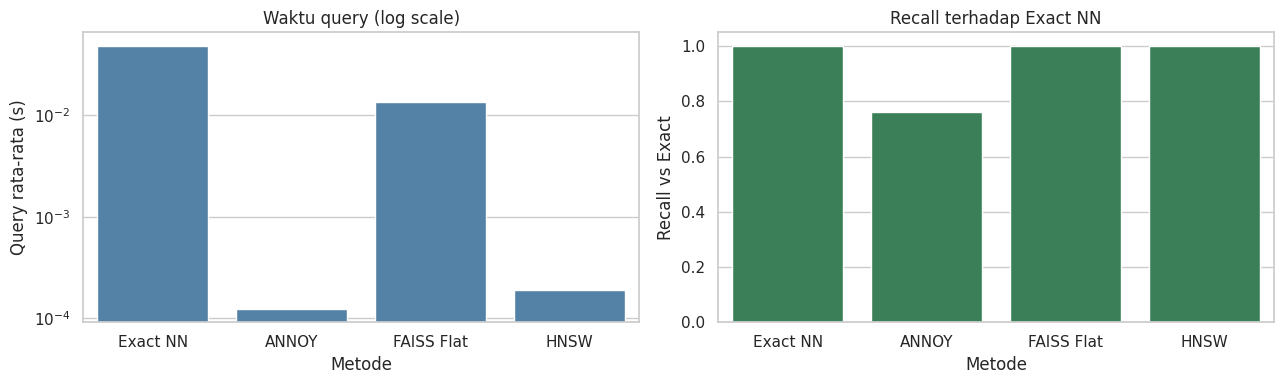

In [11]:
def avg_recall(ids_map):
    return float(np.mean([recall_at_k(ids_map[q], exact_ids[q]) for q in Q_IDS]))


perf = pd.DataFrame([
    {'Metode': 'Exact NN', 'Build (s)': 0.0, 'Query rata-rata (s)': t_exact_avg,
     'Recall vs Exact': 1.0},
    {'Metode': 'ANNOY', 'Build (s)': t_annoy_build, 'Query rata-rata (s)': t_annoy_avg,
     'Recall vs Exact': avg_recall(annoy_ids)},
    {'Metode': 'FAISS Flat', 'Build (s)': t_faiss_build, 'Query rata-rata (s)': t_faiss_avg,
     'Recall vs Exact': avg_recall(faiss_ids)},
    {'Metode': 'HNSW', 'Build (s)': t_hnsw_build, 'Query rata-rata (s)': t_hnsw_avg,
     'Recall vs Exact': avg_recall(hnsw_ids)},
])
display(perf.round(6))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.barplot(data=perf, x='Metode', y='Query rata-rata (s)', color='steelblue', ax=axes[0])
axes[0].set_yscale('log')
axes[0].set_title('Waktu query (log scale)')
sns.barplot(data=perf, x='Metode', y='Recall vs Exact', color='seagreen', ax=axes[1])
axes[1].set_ylim(0, 1.05)
axes[1].set_title('Recall terhadap Exact NN')
plt.tight_layout()
plt.show()


In [12]:
show = Q_IDS[0]
track_compare = pd.DataFrame({
    'Metode': ['Exact NN', 'ANNOY', 'FAISS Flat', 'HNSW'],
    'Top-k Track Terdekat': [
        ' | '.join(label(i) for i in exact_ids[show]),
        ' | '.join(label(i) for i in annoy_ids[show]),
        ' | '.join(label(i) for i in faiss_ids[show]),
        ' | '.join(label(i) for i in hnsw_ids[show]),
    ],
})
display(track_compare)


,Metode,Top-k Track Terdekat
0,Exact NN,row 256906 | row 472159 | row 31907 | row 539046 | row 87404 | row 810069 | ...
1,ANNOY,row 472159 | row 31907 | row 539046 | row 810069 | row 182907 | row 858990 |...
2,FAISS Flat,row 256906 | row 472159 | row 31907 | row 539046 | row 87404 | row 810069 | ...
3,HNSW,row 256906 | row 472159 | row 31907 | row 539046 | row 87404 | row 810069 | ...


## 9. Analisis dan Kesimpulan

Isi berdasarkan tabel dan grafik aktual setelah dijalankan:

- **Exact NN** selalu benar (recall = 1) tetapi paling lambat karena membandingkan query ke semua data (brute-force).
- **FAISS Flat** umumnya menghasilkan hasil identik dengan Exact NN (recall = 1) dengan waktu query jauh lebih cepat berkat optimasi SIMD/BLAS, tanpa struktur index tambahan.
- **ANNOY** dan **HNSW** adalah approximate: build index memakan waktu, tetapi query sangat cepat. Recall-nya bisa < 1; `n_trees` (ANNOY) dan `ef` (HNSW) menaikkan recall dengan biaya waktu/memori.
- Trade-off utama: **waktu build + memori** vs **kecepatan query** vs **ketelitian (recall)**. Untuk pencarian sekali-jadi, exact/FAISS Flat cukup; untuk layanan dengan jutaan query, ANN (HNSW/ANNOY) lebih efisien.


# [TAMBAHAN A] Sensitivitas Parameter

Bagian bonus. Diuji pada **subsample 100.000 data** agar ringan, dengan 2 query dan k yang sama. Recall dihitung terhadap Exact NN pada subsample yang sama.

Yang diuji:

- ANNOY: `n_trees` = 5, 10, 50
- HNSW: `ef` = 50, 100, 200 (index yang sama, cukup `set_ef`)
- FAISS IVF: `nlist` = 100, `nprobe` = 1, 10, 30 (IVF perlu tahap training, dijalankan pada subsample)


In [13]:
SUB_N = min(100000, N)
Q_SUB = [0, 1]
X_sub = X_scaled[:SUB_N]

exact_sub = {}
for q in Q_SUB:
    ids, _ = run_exact(X_sub, q)
    exact_sub[q] = ids
print('Baseline Exact NN subsample siap.')


Baseline Exact NN subsample siap.


In [14]:
rows = []

for trees in [5, 10, 50]:
    idx, bt = build_annoy(X_sub, n_trees=trees)
    times, recalls = [], []
    for q in Q_SUB:
        ids, dt = query_annoy(idx, X_sub[q], q)
        times.append(dt)
        recalls.append(recall_at_k(ids, exact_sub[q]))
    rows.append({'Metode': 'ANNOY', 'Parameter': f'n_trees={trees}',
                 'Build (s)': bt, 'Query (s)': float(np.mean(times)),
                 'Recall': float(np.mean(recalls))})

h_idx, h_bt = build_hnsw(X_sub, ef_construction=100, M=16)
for ef in [50, 100, 200]:
    times, recalls = [], []
    for q in Q_SUB:
        ids, dt = query_hnsw(h_idx, X_sub[q], q, ef=ef)
        times.append(dt)
        recalls.append(recall_at_k(ids, exact_sub[q]))
    rows.append({'Metode': 'HNSW', 'Parameter': f'ef={ef}',
                 'Build (s)': h_bt, 'Query (s)': float(np.mean(times)),
                 'Recall': float(np.mean(recalls))})

ivf = faiss.IndexIVFFlat(faiss.IndexFlatL2(D), D, 100, faiss.METRIC_L2)
t0 = time.time()
ivf.train(X_sub[:min(len(X_sub), 100000)])
ivf.add(np.ascontiguousarray(X_sub))
ivf_build_t = time.time() - t0
for nprobe in [1, 10, 30]:
    ivf.nprobe = nprobe
    times, recalls = [], []
    for q in Q_SUB:
        t0 = time.time()
        _, I = ivf.search(X_sub[q].reshape(1, -1), K + 1)
        dt = time.time() - t0
        ids = drop_self(I[0], q)
        times.append(dt)
        recalls.append(recall_at_k(ids, exact_sub[q]))
    rows.append({'Metode': 'FAISS IVF', 'Parameter': f'nprobe={nprobe}',
                 'Build (s)': ivf_build_t, 'Query (s)': float(np.mean(times)),
                 'Recall': float(np.mean(recalls))})

sensitivity_table = pd.DataFrame(rows).sort_values(['Metode', 'Parameter'])
display(sensitivity_table.round(6))


,Metode,Parameter,Build (s),Query (s),Recall
1,ANNOY,n_trees=10,1.172417,0.000078,0.90
0,ANNOY,n_trees=5,0.661139,0.000050,0.80
2,ANNOY,n_trees=50,7.480152,0.000265,1.00
6,FAISS IVF,nprobe=1,0.071521,0.002110,0.55
7,FAISS IVF,nprobe=10,0.071521,0.000157,1.00
8,FAISS IVF,nprobe=30,0.071521,0.000336,1.00
4,HNSW,ef=100,6.158405,0.000093,1.00
5,HNSW,ef=200,6.158405,0.000141,1.00
3,HNSW,ef=50,6.158405,0.000118,1.00


# [TAMBAHAN B] Skalabilitas Ukuran Data

Bagian bonus. Menguji pengaruh ukuran data terhadap **waktu build** dan **recall** pada 10 ribu dan 50 ribu data (fresh build), lalu membandingkannya dengan hasil full data dari bagian wajib.


,Ukuran,Metode,Build (s),Recall
0,10000,ANNOY,0.102283,1.00
3,50000,ANNOY,0.519799,0.80
6,955320,ANNOY,16.199134,0.76
1,10000,FAISS Flat,0.000238,1.00
4,50000,FAISS Flat,0.001137,1.00
7,955320,FAISS Flat,0.056221,1.00
2,10000,HNSW,0.442932,1.00
5,50000,HNSW,3.568894,1.00
8,955320,HNSW,96.676870,1.00


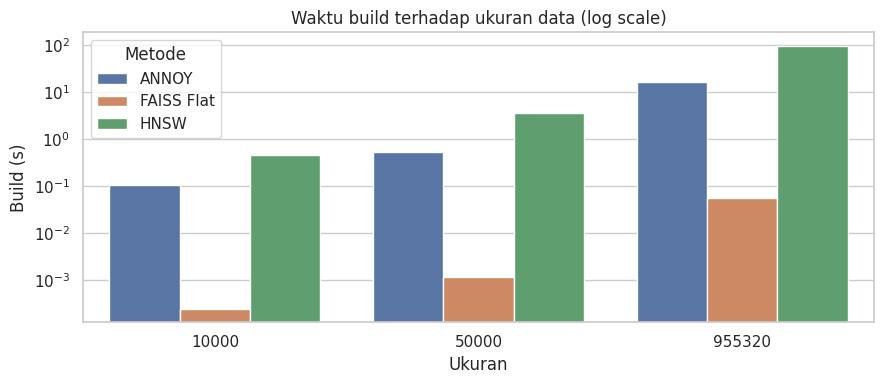

In [15]:
scale_rows = []
for size in [10000, 50000]:
    Xs = X_scaled[:size]
    qpos = 0
    exact_s, _ = run_exact(Xs, qpos)

    _, bt = build_annoy(Xs, n_trees=10)
    a_idx, _ = build_annoy(Xs, n_trees=10)
    a_ids, _ = query_annoy(a_idx, Xs[qpos], qpos)

    f_idx, f_bt = build_faiss_flat(Xs)
    f_ids, _ = query_faiss(f_idx, Xs[qpos], qpos)

    h_idx, h_bt = build_hnsw(Xs, ef_construction=100, M=16)
    h_ids, _ = query_hnsw(h_idx, Xs[qpos], qpos, ef=50)

    scale_rows.append({'Ukuran': size, 'Metode': 'ANNOY', 'Build (s)': bt,
                       'Recall': recall_at_k(a_ids, exact_s)})
    scale_rows.append({'Ukuran': size, 'Metode': 'FAISS Flat', 'Build (s)': f_bt,
                       'Recall': recall_at_k(f_ids, exact_s)})
    scale_rows.append({'Ukuran': size, 'Metode': 'HNSW', 'Build (s)': h_bt,
                       'Recall': recall_at_k(h_ids, exact_s)})

for metode, b in [('ANNOY', t_annoy_build), ('FAISS Flat', t_faiss_build), ('HNSW', t_hnsw_build)]:
    rec_map = {'ANNOY': avg_recall(annoy_ids), 'FAISS Flat': avg_recall(faiss_ids),
               'HNSW': avg_recall(hnsw_ids)}
    scale_rows.append({'Ukuran': N, 'Metode': metode, 'Build (s)': b,
                       'Recall': rec_map[metode]})

scale_table = pd.DataFrame(scale_rows).sort_values(['Metode', 'Ukuran'])
display(scale_table.round(6))

plt.figure(figsize=(9, 4))
sns.barplot(data=scale_table, x='Ukuran', y='Build (s)', hue='Metode')
plt.yscale('log')
plt.title('Waktu build terhadap ukuran data (log scale)')
plt.tight_layout()
plt.show()


## Penutup

- Bagian wajib: Exact NN vs ANNOY vs FAISS vs HNSW pada Spotify dataset dengan StandardScaler telah selesai dibandingkan (waktu build, waktu query, recall).
- Bagian `[TAMBAHAN]`: sensitivitas parameter dan skalabilitas bersifat bonus.
- File notebook ini tidak menyimpan output; hasil terisi saat dijalankan di Colab.
